# Tiny Token-Mixer — Waste Image Classification for Nicla Vision

This notebook trains a six-class waste image classifier (cardboard, glass, metal, paper, plastic, trash) at 96×96 resolution and exports it as a fully integer-quantized (int8) TensorFlow Lite model for on-device inference with OpenMV on the Arduino Nicla Vision.

**Workflow**
- Build stratified train/validation/test splits with `tf.data`.
- Define a compact convolutional token-mixer model restricted to OpenMV-compatible operators.
- Train with `sparse_categorical_crossentropy`, `EarlyStopping`, and `ReduceLROnPlateau`.
- Convert to int8 TFLite using a representative (calibration) dataset.
- Check the converted operator set and evaluate the int8 model on the validation and test splits.

**Data:** a local `images_96/` directory with one sub-folder per class (not included). The Kaggle garbage classification dataset (`asdasdasasdas/garbage-classification`) was referenced as a data source; how `images_96/` was assembled is not recorded in this notebook.

To make the model deployable on Nicla Vision with OpenMV and MicroPython, I avoided heavy or risky operators such as self-attention, MultiHeadAttention, BatchMatMul, LayerNormalization, GELU, Swish, dynamic reshape, Gather, Div, Sqrt, Rsqrt, and other complex TensorFlow operations. Instead, the model only uses deployment-friendly operators such as Conv2D, DepthwiseConv2D, Add, ReLU, Mean, FullyConnected, and Softmax. This keeps the model lightweight, fully int8-quantized, and more suitable for running on the limited memory and operator support of the Nicla Vision environment.


## 1) Prepare `tf.data` datasets

Images are read from `images_96/<class_name>/`. Class indices follow alphabetical folder order, which must match the label order used on the device. Each class is shuffled with a fixed seed and split 70/15/15 into train/validation/test.

Images are resized to 96×96 and kept as float32 in the raw 0–255 range, because the model applies its own `Rescaling(1/255)`. Augmentation is applied to the training split only and is not part of the exported model.

In [1]:
import pathlib
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers

# ---- Config ----
DATA_DIR = pathlib.Path("images_96")
IMG_SIZE = (96, 96)
BATCH_SIZE = 32
SEED = 42
TRAIN_RATIO, VAL_RATIO = 0.70, 0.15   # test gets the remaining 0.15
AUTOTUNE = tf.data.AUTOTUNE

# Class order MUST match the deployment label file (alphabetical).
class_names = sorted([d.name for d in DATA_DIR.iterdir() if d.is_dir()])
num_classes = len(class_names)
print("Classes:", class_names)

# ---- Build a stratified, deterministic file-level split ----
# Splitting per class guarantees every class keeps the same proportion
# in train/val/test, and the fixed seed makes the split reproducible.
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}
train_paths, train_labels = [], []
val_paths, val_labels = [], []
test_paths, test_labels = [], []

for label, cname in enumerate(class_names):
    files = sorted(str(p) for p in (DATA_DIR / cname).glob("*") if p.suffix.lower() in IMG_EXT)
    rng = np.random.default_rng(SEED + label)        # per-class deterministic shuffle
    files = list(np.array(files)[rng.permutation(len(files))])
    n = len(files)
    n_tr, n_va = int(TRAIN_RATIO * n), int(VAL_RATIO * n)
    train_paths += files[:n_tr];          train_labels += [label] * n_tr
    val_paths   += files[n_tr:n_tr+n_va]; val_labels   += [label] * n_va
    test_paths  += files[n_tr+n_va:];     test_labels  += [label] * (n - n_tr - n_va)

print(f"Split sizes -> train: {len(train_paths)}, val: {len(val_paths)}, test: {len(test_paths)}")

# ---- Training-only augmentation (kept in the data pipeline, NOT in the model) ----
# This never enters the exported model, so it has zero effect on the TFLite op list.
# Purpose: robustness to camera lighting / angle / white-balance drift on Nicla Vision.
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")

def load_image(path, label):
    # Decode to float32 in the RAW 0-255 range. The model's internal Rescaling
    # divides by 255, so representative/calibration data must also stay in 0-255.
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    return tf.cast(img, tf.float32), label

def make_dataset(paths, labels, shuffle=False, augment=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    if augment:
        ds = ds.map(lambda x, y: (tf.clip_by_value(data_augmentation(x, training=True), 0.0, 255.0), y),
                    num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(train_paths, train_labels, shuffle=True,  augment=True)
val_ds   = make_dataset(val_paths,   val_labels,   shuffle=False, augment=False)
test_ds  = make_dataset(test_paths,  test_labels,  shuffle=False, augment=False)

Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Split sizes -> train: 9728, val: 2084, test: 2089


## 2) Model: compact convolutional token-mixer

The model follows the token-mixer idea (MLP-Mixer inspired): each block alternates spatial (token) mixing and channel mixing, each with a residual connection. To stay within the OpenMV operator set, token mixing is a 3×3 depthwise convolution and channel mixing is a 1×1 expand/project pair, using BatchNorm (folded into the convolutions at conversion) and ReLU instead of LayerNorm and GELU.

Layout: a three-layer strided convolutional stem (96 → 12), two mixer blocks at 12×12×48, a depthwise-separable downsample to 6×6×80, two mixer blocks at 6×6×80, then global average pooling and a small dense head.

In [2]:
from tensorflow.keras import layers, models

def conv_bn_relu(x, filters, stride, name, kernel=3):
    # Conv(no bias) -> BN -> ReLU; BN folds into the Conv at int8 conversion.
    x = layers.Conv2D(filters, kernel, strides=stride, padding="same",
                      use_bias=False, name=f"{name}_conv")(x)
    x = layers.BatchNormalization(name=f"{name}_bn")(x)
    x = layers.ReLU(name=f"{name}_relu")(x)
    return x

def sep_downsample(x, out_ch, name):
    # Depthwise-separable stride-2 downsample. Far cheaper than a full 3x3 conv
    # (DW 3x3 + 1x1 pointwise), which is the key parameter saving vs V3b.
    x = layers.DepthwiseConv2D(3, strides=2, padding="same", use_bias=False, name=f"{name}_dw")(x)
    x = layers.BatchNormalization(name=f"{name}_dw_bn")(x)
    x = layers.ReLU(name=f"{name}_dw_relu")(x)
    x = layers.Conv2D(out_ch, 1, use_bias=False, name=f"{name}_pw")(x)
    x = layers.BatchNormalization(name=f"{name}_pw_bn")(x)
    x = layers.ReLU(name=f"{name}_pw_relu")(x)
    return x

def mixer_block(x, channels, mlp_ratio, block_id):
    shortcut = x
    y = layers.DepthwiseConv2D(3, padding="same", use_bias=False, name=f"b{block_id}_dw")(x)
    y = layers.BatchNormalization(name=f"b{block_id}_dw_bn")(y)
    y = layers.ReLU(name=f"b{block_id}_dw_relu")(y)
    x = layers.Add(name=f"b{block_id}_spatial_add")([shortcut, y])

    shortcut = x
    hidden = channels * mlp_ratio
    y = layers.Conv2D(hidden, 1, use_bias=False, name=f"b{block_id}_pw_expand")(x)
    y = layers.BatchNormalization(name=f"b{block_id}_pw_expand_bn")(y)
    y = layers.ReLU(name=f"b{block_id}_pw_expand_relu")(y)
    y = layers.Conv2D(channels, 1, use_bias=False, name=f"b{block_id}_pw_project")(y)
    y = layers.BatchNormalization(name=f"b{block_id}_pw_project_bn")(y)
    x = layers.Add(name=f"b{block_id}_channel_add")([shortcut, y])
    return x

def build_c1_token_mixer(input_shape=(96, 96, 3), num_classes=6,
                         stage1_dim=48, stage2_dim=80, mlp_ratio=2):
    inputs = layers.Input(shape=input_shape, name="input_image")
    x = layers.Rescaling(1.0 / 255.0, name="rescale")(inputs)

    # Stem: 96 -> 48 -> 24 -> 12, up to stage1_dim channels
    x = conv_bn_relu(x, stage1_dim // 4, 2, "stem1")
    x = conv_bn_relu(x, stage1_dim // 2, 2, "stem2")
    x = conv_bn_relu(x, stage1_dim,      2, "stem3")

    # Stage 1: two mixer blocks at 12x12 (narrow channels keep RAM low)
    x = mixer_block(x, stage1_dim, mlp_ratio, 1)
    x = mixer_block(x, stage1_dim, mlp_ratio, 2)

    # Cheap separable transition: 12 -> 6 and widen
    x = sep_downsample(x, stage2_dim, "transition")

    # Stage 2: two mixer blocks at 6x6 (channels are cheap here)
    x = mixer_block(x, stage2_dim, mlp_ratio, 3)
    x = mixer_block(x, stage2_dim, mlp_ratio, 4)

    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dense(stage2_dim, activation="relu", name="head_dense")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)
    return models.Model(inputs, outputs, name="c1_token_mixer")

model = build_c1_token_mixer(num_classes=num_classes)
model.summary()

Model: "c1_token_mixer"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_image (InputLayer)    [(None, 96, 96, 3)]          0         []                            
                                                                                                  
 rescale (Rescaling)         (None, 96, 96, 3)            0         ['input_image[0][0]']         
                                                                                                  
 stem1_conv (Conv2D)         (None, 48, 48, 12)           324       ['rescale[0][0]']             
                                                                                                  
 stem1_bn (BatchNormalizati  (None, 48, 48, 12)           48        ['stem1_conv[0][0]']          
 on)                                                                                 

## 3) Train the model

Adam (learning rate 1e-3) with `sparse_categorical_crossentropy`, up to 80 epochs. `EarlyStopping` (restoring the best weights) and `ReduceLROnPlateau` monitor validation loss. The trained model is saved as `c1_token_mixer.keras` for conversion.

In [3]:
def train_one_seed(run_seed):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(run_seed)

    model = build_baseline_token_mixer(
        input_shape=(96, 96, 3),
        num_classes=num_classes,
        patch_size=8,
        embed_dim=48,
        num_blocks=3,
        mlp_ratio=2
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    checkpoint_path = f"openmv_safe_tiny_token_mixer_v13_seed_{run_seed}.keras"

    model_checkpoint = callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )

    early_stop = callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=15,
        restore_best_weights=True,
        verbose=1
    )

    reduce_lr = callbacks.ReduceLROnPlateau(
        monitor="val_accuracy",
        mode="max",
        factor=0.5,
        patience=6,
        min_lr=1e-5,
        verbose=1
    )

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=80,
        callbacks=[model_checkpoint, early_stop, reduce_lr],
        verbose=1
    )

    best_val_acc = max(history.history["val_accuracy"])
    best_epoch = int(np.argmax(history.history["val_accuracy"])) + 1

    return {
        "seed": run_seed,
        "best_val_accuracy": best_val_acc,
        "best_epoch": best_epoch,
        "model_path": checkpoint_path,
        "history": history
    }

In [4]:
# Stronger augmentation to match the larger V3b capacity (training pipeline only).
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.10, 0.10),
    layers.RandomContrast(0.15),
], name="data_augmentation")

In [5]:
from tensorflow.keras import callbacks

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

cbs = [
    callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=80,                 # more capacity + stronger aug -> allow more epochs
    callbacks=cbs,
)

val_loss, val_acc = model.evaluate(val_ds)
print(f"V3b Keras validation accuracy: {val_acc:.4f}")

# IMPORTANT: save under the V3b name so the int8 conversion picks up the right model.
model.save("c1_token_mixer.keras")

Epoch 1/80
304/304 [==============================] - 10s 25ms/step - loss: 1.4394 - accuracy: 0.4420 - val_loss: 2.3232 - val_accuracy: 0.2001 - lr: 0.0010
Epoch 2/80
304/304 [==============================] - 7s 23ms/step - loss: 1.2491 - accuracy: 0.5323 - val_loss: 1.5791 - val_accuracy: 0.4040 - lr: 0.0010
Epoch 3/80
304/304 [==============================] - 7s 23ms/step - loss: 1.1522 - accuracy: 0.5719 - val_loss: 1.3722 - val_accuracy: 0.4890 - lr: 0.0010
Epoch 4/80
304/304 [==============================] - 7s 23ms/step - loss: 1.0943 - accuracy: 0.5958 - val_loss: 2.3962 - val_accuracy: 0.2821 - lr: 0.0010
Epoch 5/80
304/304 [==============================] - 7s 22ms/step - loss: 1.0571 - accuracy: 0.6098 - val_loss: 1.3058 - val_accuracy: 0.5298 - lr: 0.0010
Epoch 6/80
304/304 [==============================] - 7s 23ms/step - loss: 1.0095 - accuracy: 0.6273 - val_loss: 1.5966 - val_accuracy: 0.4535 - lr: 0.0010
Epoch 7/80
304/304 [==============================] - 7s 23ms/s

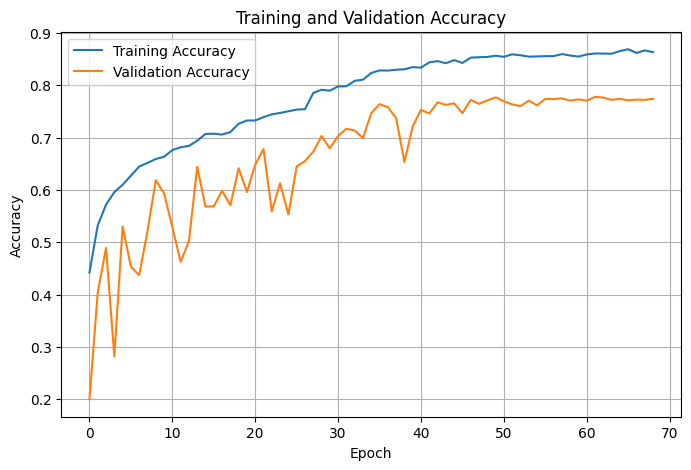

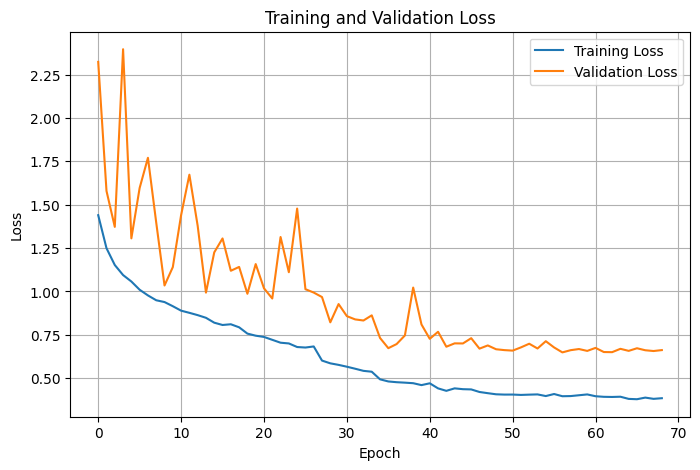

In [6]:
import matplotlib.pyplot as plt

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

              precision    recall  f1-score   support

   cardboard     0.7817    0.7982    0.7899       332
       glass     0.8239    0.7733    0.7978       375
       metal     0.7544    0.8173    0.7846       312
       paper     0.7670    0.7781    0.7725       347
     plastic     0.7937    0.7405    0.7662       343
       trash     0.7258    0.7413    0.7335       375

    accuracy                         0.7735      2084
   macro avg     0.7744    0.7748    0.7741      2084
weighted avg     0.7747    0.7735    0.7736      2084



<Figure size 800x800 with 0 Axes>

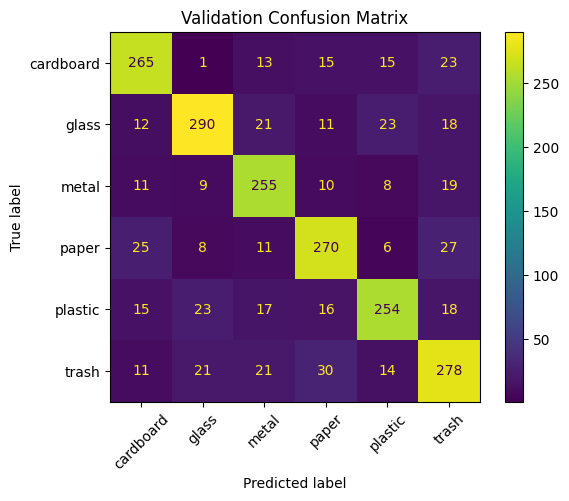

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Collect true labels and predicted labels
y_true = []
y_pred = []

for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    pred_labels = np.argmax(preds, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(pred_labels)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Print classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

# Plot confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(
    xticks_rotation=45,
    values_format="d",
    cmap=None
)
plt.title("Validation Confusion Matrix")
plt.show()

## 4) Convert to fully integer-quantized TFLite

Calibration uses a representative dataset of 200 unaugmented training images (float32, raw 0–255 range). The converter produces int8 operators with int8 input and output tensors. The converted model is then checked against an OpenMV-compatible operator allowlist and evaluated on the validation and test splits with the TFLite interpreter.

In [8]:
import os
import numpy as np
import tensorflow as tf

KERAS_MODEL_PATH = "c1_token_mixer.keras"
TFLITE_MODEL_PATH = "c1_token_mixer_int8.tflite"

saved_model = tf.keras.models.load_model(KERAS_MODEL_PATH)

# Representative dataset: CLEAN training images (augment=False), RAW 0-255 range.
# The model has an internal Rescaling(1/255), so calibration data must NOT be
# pre-divided and must NOT be augmented (we want the true input distribution).
calib_ds = make_dataset(train_paths, train_labels, shuffle=False, augment=False)

def representative_dataset():
    count = 0
    for images, _ in calib_ds.unbatch().batch(1):
        yield [tf.cast(images, tf.float32)]   # shape (1, 96, 96, 3), values in 0-255
        count += 1
        if count >= 200:                      # 200 samples is plenty for calibration
            break

converter = tf.lite.TFLiteConverter.from_keras_model(saved_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_model = converter.convert()
with open(TFLITE_MODEL_PATH, "wb") as f:
    f.write(tflite_model)

size_kb = os.path.getsize(TFLITE_MODEL_PATH) / 1024
print(f"Saved: {TFLITE_MODEL_PATH}")
print(f"Size: {size_kb:.2f} KB")

INFO:tensorflow:Assets written to: <tmpdir>/assets


INFO:tensorflow:Assets written to: <tmpdir>/assets
.../site-packages/tensorflow/lite/python/convert.py:953: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
2026-05-28 16:03:56.097703: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:378] Ignored output_format.
2026-05-28 16:03:56.097725: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:381] Ignored drop_control_dependency.
2026-05-28 16:03:56.098063: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: <tmpdir>
2026-05-28 16:03:56.104470: I tensorflow/cc/saved_model/reader.cc:51] Reading meta graph with tags { serve }
2026-05-28 16:03:56.104481: I tensorflow/cc/saved_model/reader.cc:146] Reading SavedModel debug info (if present) from: <tmpdir>
2026-05-28 16:03:56.116284: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:388] MLIR V1 optimization pass is not enabled
2026-05-28 16:03:56.120494: I tensorflow/cc/

Saved: c1_token_mixer_int8.tflite
Size: 142.51 KB


2026-05-28 16:03:57.333969: W tensorflow/core/kernels/data/cache_dataset_ops.cc:858] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8


In [9]:
interpreter = tf.lite.Interpreter(model_path=TFLITE_MODEL_PATH)
interpreter.allocate_tensors()

ops = sorted(set(op["op_name"] for op in interpreter._get_ops_details()))
print("TFLite operators:", ops)

# Safety gate: everything must be in the OpenMV-safe set. DELEGATE is a desktop-only
# interpreter artifact, not a real model op dependency, so it is allowed/ignored here.
SAFE_OPS = {"ADD", "CONV_2D", "DEPTHWISE_CONV_2D", "FULLY_CONNECTED",
            "MEAN", "SOFTMAX", "AVERAGE_POOL_2D", "MAX_POOL_2D",
            "RELU", "RELU6", "RESHAPE", "QUANTIZE", "DEQUANTIZE"}
unsafe = [o for o in ops if o not in SAFE_OPS and o != "DELEGATE"]
print("Unsafe ops:", unsafe if unsafe else "NONE - model is OpenMV-safe")

in_d = interpreter.get_input_details()[0]
out_d = interpreter.get_output_details()[0]
print("Input  dtype:", in_d["dtype"].__name__, "| quant:", in_d["quantization"])
print("Output dtype:", out_d["dtype"].__name__, "| quant:", out_d["quantization"])

TFLite operators: ['ADD', 'CONV_2D', 'DELEGATE', 'DEPTHWISE_CONV_2D', 'FULLY_CONNECTED', 'MEAN', 'SOFTMAX']
Unsafe ops: NONE - model is OpenMV-safe
Input  dtype: int8 | quant: (1.0, -128)
Output dtype: int8 | quant: (0.00390625, -128)


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


In [10]:
def evaluate_int8_tflite(tflite_path, dataset):
    # Run the quantized model exactly the way OpenMV will: feed raw images,
    # quantize to int8 using the model's own input scale/zero-point, argmax the output.
    interp = tf.lite.Interpreter(model_path=tflite_path)
    interp.allocate_tensors()

    in_idx = interp.get_input_details()[0]["index"]
    out_idx = interp.get_output_details()[0]["index"]
    in_scale, in_zp = interp.get_input_details()[0]["quantization"]

    correct, total = 0, 0
    for images, labels in dataset:
        images_np = images.numpy()
        labels_np = labels.numpy()
        for i in range(images_np.shape[0]):
            img = images_np[i:i+1].astype(np.float32)           # raw 0-255
            q = np.round(img / in_scale + in_zp)                # quantize to int8
            q = np.clip(q, -128, 127).astype(np.int8)

            interp.set_tensor(in_idx, q)
            interp.invoke()
            out = interp.get_tensor(out_idx)                    # int8 logits/probs

            pred = int(np.argmax(out[0]))                       # argmax is scale-invariant
            correct += int(pred == int(labels_np[i]))
            total += 1
    return correct / total

# Validation accuracy (same metric as V1's 0.7065 -> use this to accept/reject)
val_int8_acc = evaluate_int8_tflite(TFLITE_MODEL_PATH, val_ds)
print(f"V2 int8 TFLite VAL accuracy:  {val_int8_acc:.4f}  (V1 baseline: 0.7065)")

# Test accuracy: report ONCE here as the final held-out number. Do not tune on it.
test_int8_acc = evaluate_int8_tflite(TFLITE_MODEL_PATH, test_ds)
print(f"V2 int8 TFLite TEST accuracy: {test_int8_acc:.4f}")

V2 int8 TFLite VAL accuracy:  0.7745  (V1 baseline: 0.7065)
V2 int8 TFLite TEST accuracy: 0.7927


In [11]:
# Evaluate the int8 TFLite model on the validation dataset
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

input_index = input_details[0]["index"]
output_index = output_details[0]["index"]

input_scale, input_zero_point = input_details[0]["quantization"]
output_scale, output_zero_point = output_details[0]["quantization"]

print("Input details:", input_details[0])
print("Output details:", output_details[0])

correct = 0
total = 0

for images, labels in val_ds:
    images_np = images.numpy()
    labels_np = labels.numpy()

    for i in range(images_np.shape[0]):
        img = images_np[i:i+1].astype(np.float32)

        # Quantize input image
        img_int8 = img / input_scale + input_zero_point
        img_int8 = np.clip(np.round(img_int8), -128, 127).astype(np.int8)

        interpreter.set_tensor(input_index, img_int8)
        interpreter.invoke()

        output_int8 = interpreter.get_tensor(output_index)

        # Dequantization is optional for argmax, but useful for checking confidence
        output_float = (output_int8.astype(np.float32) - output_zero_point) * output_scale

        pred_label = np.argmax(output_float[0])
        true_label = labels_np[i]

        if pred_label == true_label:
            correct += 1

        total += 1

tflite_acc = correct / total
print(f"Validation accuracy of int8 TFLite model: {tflite_acc:.4f}")

Input details: {'name': 'serving_default_input_image:0', 'index': 0, 'shape': array([ 1, 96, 96,  3], dtype=int32), 'shape_signature': array([-1, 96, 96,  3], dtype=int32), 'dtype': <class 'numpy.int8'>, 'quantization': (1.0, -128), 'quantization_parameters': {'scales': array([1.], dtype=float32), 'zero_points': array([-128], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}
Output details: {'name': 'StatefulPartitionedCall:0', 'index': 68, 'shape': array([1, 6], dtype=int32), 'shape_signature': array([-1,  6], dtype=int32), 'dtype': <class 'numpy.int8'>, 'quantization': (0.00390625, -128), 'quantization_parameters': {'scales': array([0.00390625], dtype=float32), 'zero_points': array([-128], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}
Validation accuracy of int8 TFLite model: 0.7745


## 5) Inspect the quantized TFLite model

Reload the `.tflite` file and print its size, input/output tensor details (dtype, shape, scale, zero point), and the operators used by the converted graph.

In [13]:
# Part 6: Sanity Check for the Quantized TFLite Model

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import os

TFLITE_MODEL_PATH = "c1_token_mixer_int8.tflite"

# Load the TFLite model
interpreter = tf.lite.Interpreter(model_path=TFLITE_MODEL_PATH)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

input_index = input_details[0]["index"]
output_index = output_details[0]["index"]

input_scale, input_zero_point = input_details[0]["quantization"]
output_scale, output_zero_point = output_details[0]["quantization"]

print("TFLite model path:", TFLITE_MODEL_PATH)
print("TFLite model size:", round(os.path.getsize(TFLITE_MODEL_PATH) / 1024, 2), "KB")
print()
print("Input details:")
print(input_details[0])
print()
print("Output details:")
print(output_details[0])
print()
print("Input scale:", input_scale)
print("Input zero point:", input_zero_point)
print("Output scale:", output_scale)
print("Output zero point:", output_zero_point)

TFLite model path: c1_token_mixer_int8.tflite
TFLite model size: 142.51 KB

Input details:
{'name': 'serving_default_input_image:0', 'index': 0, 'shape': array([ 1, 96, 96,  3], dtype=int32), 'shape_signature': array([-1, 96, 96,  3], dtype=int32), 'dtype': <class 'numpy.int8'>, 'quantization': (1.0, -128), 'quantization_parameters': {'scales': array([1.], dtype=float32), 'zero_points': array([-128], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}

Output details:
{'name': 'StatefulPartitionedCall:0', 'index': 68, 'shape': array([1, 6], dtype=int32), 'shape_signature': array([-1,  6], dtype=int32), 'dtype': <class 'numpy.int8'>, 'quantization': (0.00390625, -128), 'quantization_parameters': {'scales': array([0.00390625], dtype=float32), 'zero_points': array([-128], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}

Input scale: 1.0
Input zero point: -128
Output scale: 0.00390625
Output zero point: -128


In [14]:
# Inspect operators used by the TFLite model
ops_details = interpreter._get_ops_details()
ops = sorted(set(op["op_name"] for op in ops_details))

print("TFLite operators:")
for op in ops:
    print(op)

TFLite operators:
ADD
CONV_2D
DELEGATE
DEPTHWISE_CONV_2D
FULLY_CONNECTED
MEAN
SOFTMAX
